# Scania APS — initial data quality review

**Purpose:** Explore the official **training** dataset before any modelling or irreversible preprocessing.

- Use shared project loaders and quality helpers.
- Document missingness, sparsity, duplicates, and class imbalance.
- **Do not** use the held-out test set for exploratory decisions.
- **No final preprocessing choices** are made in this notebook.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.load_data import load_training_data
from src.data.preprocess import (
    class_distribution,
    duplicate_count,
    find_constant_columns,
    find_high_missing_columns,
    find_zero_heavy_columns,
    missingness_summary,
    split_features_target,
)

train = load_training_data()
X, y = split_features_target(train)

## Dataset shape and structure

In [2]:
print(f"Rows: {train.shape[0]:,}")
print(f"Columns: {train.shape[1]:,} (170 features + target `class`)")
train.shape

Rows: 60,000
Columns: 171 (170 features + target `class`)


(60000, 171)

In [3]:
train.head()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


## Target class distribution

In [4]:
target_summary = class_distribution(train)
target_summary

,count,percent
class,,
neg,59000,98.333333
pos,1000,1.666667


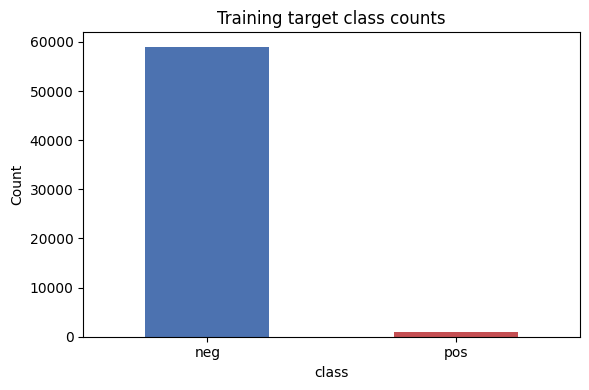

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
target_summary["count"].plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title("Training target class counts")
ax.set_xlabel("class")
ax.set_ylabel("Count")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

## Missing values (features only)

In [6]:
total_missing_pct = X.isna().sum().sum() / X.size * 100
print(f"Total missing share across feature cells: {total_missing_pct:.2f}%")

Total missing share across feature cells: 8.33%


In [7]:
miss = missingness_summary(X)
miss.head(15)

,missing_count,missing_percent
br_000,49264,82.106667
bq_000,48722,81.203333
bp_000,47740,79.566667
bo_000,46333,77.221667
ab_000,46329,77.215000
cr_000,46329,77.215000
bn_000,44009,73.348333
bm_000,39549,65.915000
bl_000,27277,45.461667
bk_000,23034,38.390000


In [8]:
high_missing = find_high_missing_columns(X, threshold=0.75)
print(f"Features with >= 75% missing: {len(high_missing)}")
high_missing

Features with >= 75% missing: 6


['ab_000', 'bo_000', 'bp_000', 'bq_000', 'br_000', 'cr_000']

## Duplicates, constant features, and zero-heavy features

In [9]:
n_duplicates = duplicate_count(train)
print(f"Completely duplicated rows: {n_duplicates}")

Completely duplicated rows: 0


In [10]:
constant_cols = find_constant_columns(train)
print(f"Constant feature columns: {len(constant_cols)}")
constant_cols

Constant feature columns: 1


['cd_000']

In [11]:
zero_heavy = find_zero_heavy_columns(train, threshold=0.95)
print(f"Features with >= 95% zeros (non-missing): {len(zero_heavy)}")
zero_heavy.head(20)

Features with >= 95% zeros (non-missing): 30


,column,zero_percent
0,ch_000,99.977846
1,as_000,99.964629
2,au_000,99.897256
3,ag_000,99.669639
4,dj_000,99.648170
5,dl_000,99.601729
6,ef_000,99.554787
7,dm_000,99.540998
8,dz_000,99.488451
9,dk_000,99.432072


## Summary and limitations

**Findings (computed from the local training file):**

- Strong class imbalance: most rows are `neg`; failures (`pos`) are rare.
- Missing values affect a meaningful fraction of feature cells overall; missingness is concentrated in a subset of columns.
- Several features exceed 75% missing; at least one feature appears constant.
- Many numeric features are dominated by zeros among observed values.
- No fully duplicated training rows were detected.

**Limitations:**

- Feature names are anonymised; we do not infer sensor semantics here.
- This review is descriptive only — **no imputation, dropping, or scaling** has been applied.
- The official **test** dataset was not used and remains for final evaluation only.

**Next step for the group:** agree on handling missing, constant, and zero-heavy features and on imbalance strategy before fitting baseline models.